# Structural Equation Modeling (SEM): Engagement, Self-Efficacy, and Academic Performance

This Notebook introduces Structural Equation Modeling using observed indicators and latent constructs.

# 構造方程式モデリング（SEM）：学習参加・自己効力感・学業成果

このNotebookでは、複数の観測指標から潜在変数を作り、その潜在変数同士の関係を分析します。

## 1. Learning Objectives / 学習目標

- Understand observed and latent variables
- Understand measurement and structural models
- Understand how SEM extends Path Analysis
- Estimate latent constructs from multiple indicators
- Estimate structural paths
- Calculate direct, indirect, and total effects
- Understand the idea of model fit
- Understand assumptions and limitations

- 観測変数と潜在変数を理解する
- 測定モデルと構造モデルを理解する
- パス解析からSEMへの拡張を理解する
- 複数指標から潜在概念を推定する
- 潜在変数間のパスを推定する
- 直接・間接・総効果を理解する
- モデル適合度の考え方を理解する
- SEMの限界を理解する

## 2. Use Case / ユースケース

A school wants to study three concepts:

1. Learning Engagement
2. Academic Self-Efficacy
3. Academic Performance

Each concept is represented by three observed indicators.

学校が「学習参加」「自己効力感」「学業成果」という直接観測しにくい概念の関係を分析するケースです。

## 3. Observed vs Latent Variables / 観測変数と潜在変数

Observed variables are directly recorded values such as attendance or exam scores.

Latent variables are theoretical constructs that cannot be measured directly.

SEM represents a latent construct using several observed indicators.

SEMの第一歩は「直接測れるもの」と「直接は測れない概念」を分けることです。

## 4. Measurement Model / 測定モデル

The measurement model defines how observed indicators represent latent constructs.

**Learning Engagement**
- Study Hours
- Attendance
- Assignment Completion

**Academic Self-Efficacy**
- Confidence in Math
- Confidence in Learning
- Persistence

**Academic Performance**
- Math Score
- Reading Score
- Problem-Solving Score

測定モデルは「潜在概念を何によって測るのか」を表します。

## 5. Structural Model / 構造モデル

The structural model defines relationships among latent variables.

Our hypothesis is:

`Learning Engagement → Academic Self-Efficacy`

`Learning Engagement → Academic Performance`

`Academic Self-Efficacy → Academic Performance`

つまり、学習参加は学業成果へ直接つながる経路と、自己効力感を経由する間接経路の両方を持つと仮定します。

## 6. Connection to Chapter 12 / 12章とのつながり

A useful learning sequence is:

`Multiple Regression → Path Analysis → SEM`

Path Analysis models paths among observed variables.

SEM adds latent variables and a measurement model.

12章で学んだ「矢印のつながり」に、13章では「潜在変数」が加わります。

## 7. Import Libraries / ライブラリの読み込み

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis
pd.set_option("display.max_columns",None)

## 8. Load and Inspect Data / データの読み込み

In [2]:
paths=[Path("../data/student_sem_model.csv"),Path("13_structural_equation_modeling/data/student_sem_model.csv"),Path("data/student_sem_model.csv")]
data_path=next((p for p in paths if p.exists()),None)
if data_path is None: raise FileNotFoundError("student_sem_model.csv was not found.")
df=pd.read_csv(data_path)
df.head()

,student_id,study_hours_week,attendance_rate,assignment_completion_rate,confidence_math,confidence_learning,persistence_score,math_score,reading_score,problem_solving_score
0,S001,8.19,88.45,86.19,65.93,69.17,65.92,75.24,73.69,69.73
1,S002,6.35,85.68,76.51,69.47,70.44,72.25,75.13,71.36,61.44
2,S003,10.98,95.97,92.66,78.42,83.73,75.59,75.87,83.46,78.60
3,S004,10.81,86.66,93.18,66.36,67.65,77.71,85.29,91.15,84.22
4,S005,4.32,75.14,67.58,56.83,59.01,65.49,72.39,80.75,70.68


In [3]:
print("Shape:",df.shape)
df.info()

Shape: (400, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  400 non-null    object 
 1   study_hours_week            400 non-null    float64
 2   attendance_rate             400 non-null    float64
 3   assignment_completion_rate  400 non-null    float64
 4   confidence_math             400 non-null    float64
 5   confidence_learning         400 non-null    float64
 6   persistence_score           400 non-null    float64
 7   math_score                  400 non-null    float64
 8   reading_score               400 non-null    float64
 9   problem_solving_score       400 non-null    float64
dtypes: float64(9), object(1)
memory usage: 31.4+ KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
study_hours_week,400.0,8.91,2.24,2.61,7.47,8.94,10.49,16.00
attendance_rate,400.0,86.39,6.35,64.69,82.36,86.35,90.70,100.00
assignment_completion_rate,400.0,85.92,7.37,63.00,81.10,86.16,90.96,100.00
confidence_math,400.0,67.87,9.58,39.12,61.36,67.94,73.87,95.31
confidence_learning,400.0,69.83,9.69,37.36,62.77,69.40,76.72,96.32
persistence_score,400.0,68.85,9.32,44.93,62.28,68.27,75.12,98.74
math_score,400.0,73.52,8.00,50.47,68.03,73.00,79.44,100.00
reading_score,400.0,74.87,7.99,51.76,69.31,74.90,80.25,97.42
problem_solving_score,400.0,72.68,8.41,50.26,66.73,72.96,78.65,97.82


## 9. Correlation Matrix / 相関行列

In [5]:
observed=[
"study_hours_week","attendance_rate","assignment_completion_rate",
"confidence_math","confidence_learning","persistence_score",
"math_score","reading_score","problem_solving_score"]
corr=df[observed].corr()
corr.round(2)

,study_hours_week,attendance_rate,assignment_completion_rate,confidence_math,confidence_learning,persistence_score,math_score,reading_score,problem_solving_score
study_hours_week,1.00,0.67,0.72,0.43,0.47,0.39,0.45,0.37,0.48
attendance_rate,0.67,1.00,0.66,0.43,0.44,0.36,0.42,0.38,0.44
assignment_completion_rate,0.72,0.66,1.00,0.39,0.45,0.38,0.38,0.38,0.44
confidence_math,0.43,0.43,0.39,1.00,0.74,0.62,0.52,0.45,0.55
confidence_learning,0.47,0.44,0.45,0.74,1.00,0.66,0.53,0.45,0.54
persistence_score,0.39,0.36,0.38,0.62,0.66,1.00,0.47,0.44,0.50
math_score,0.45,0.42,0.38,0.52,0.53,0.47,1.00,0.65,0.76
reading_score,0.37,0.38,0.38,0.45,0.45,0.44,0.65,1.00,0.69
problem_solving_score,0.48,0.44,0.44,0.55,0.54,0.50,0.76,0.69,1.00


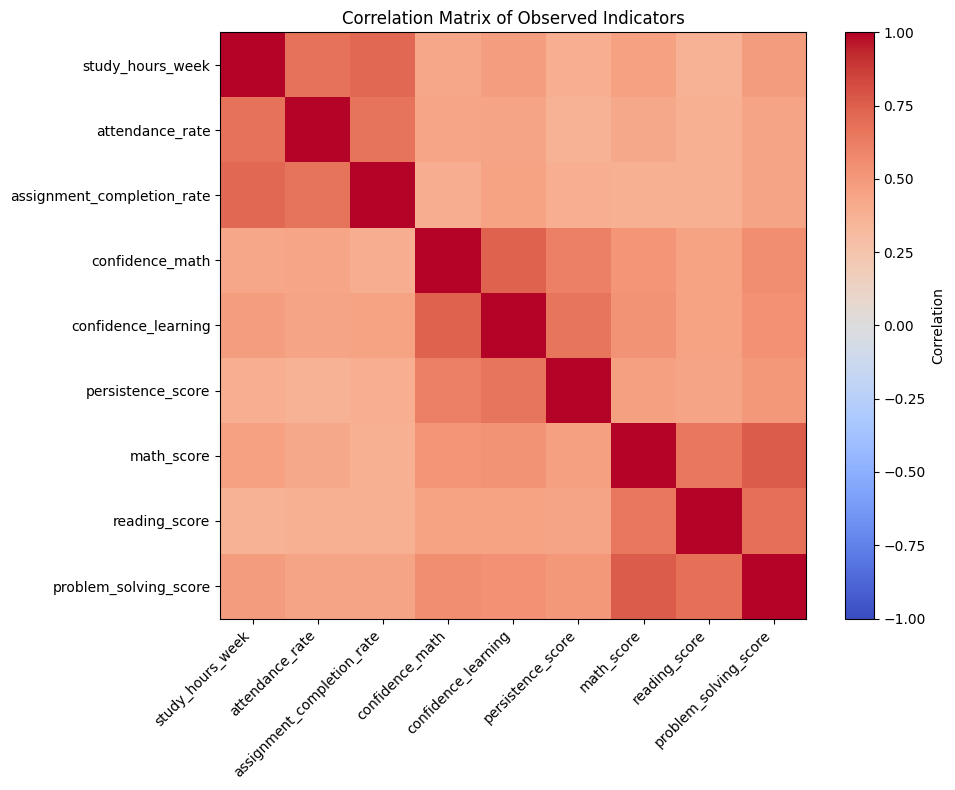

In [6]:
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr.values,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(observed)),labels=observed,rotation=45,ha="right")
ax.set_yticks(range(len(observed)),labels=observed)
fig.colorbar(im,ax=ax,label="Correlation")
ax.set_title("Correlation Matrix of Observed Indicators")
plt.tight_layout(); plt.show()

## 10. Educational SEM Strategy / このNotebookでのSEMの進め方

A full SEM package estimates the measurement and structural models simultaneously.

For educational clarity, this Notebook decomposes the process into two steps using packages already used in this repository:

1. Estimate one latent score for each construct from its indicators using Factor Analysis.
2. Estimate the structural paths among the resulting latent scores.

This is a **two-step approximation for learning**, not a replacement for full-information SEM software.

本来のSEMは測定モデルと構造モデルを同時推定します。

ここでは仕組みを理解しやすくするため、まず因子分析で潜在スコアを作り、その後パス解析を行います。これは学習用の近似であり、厳密なSEMそのものではありません。

## 11. Standardize Indicators / 観測指標を標準化する

In [7]:
Z=pd.DataFrame(StandardScaler().fit_transform(df[observed]),columns=observed,index=df.index)
Z.head()

,study_hours_week,attendance_rate,assignment_completion_rate,confidence_math,confidence_learning,persistence_score,math_score,reading_score,problem_solving_score
0,-0.322167,0.325128,0.037259,-0.202722,-0.067752,-0.314845,0.215187,-0.147731,-0.351613
1,-1.143630,-0.111735,-1.278193,0.167413,0.063515,0.364896,0.201428,-0.439853,-1.338317
2,0.923420,1.511124,0.916491,1.103208,1.437165,0.723559,0.293988,1.077173,0.704125
3,0.847524,0.042823,0.987156,-0.157762,-0.224859,0.951213,1.472255,2.041299,1.373037
4,-2.049918,-1.774023,-2.491724,-1.154201,-1.117887,-0.361020,-0.141295,0.737409,-0.238541


## 12. Estimate Learning Engagement / Learning Engagementを推定する

One-factor analysis is applied to its three indicators.

3つの観測指標から1つの潜在スコアを抽出します。

In [8]:
eng_cols=["study_hours_week","attendance_rate","assignment_completion_rate"]
fa_eng=FactorAnalysis(n_components=1,random_state=42)
eng_score=fa_eng.fit_transform(Z[eng_cols]).ravel()
eng_load=pd.Series(fa_eng.components_[0],index=eng_cols,name="loading")
eng_load

study_hours_week             -0.850079
attendance_rate              -0.791564
assignment_completion_rate   -0.840335
Name: loading, dtype: float64

## 13. Estimate Academic Self-Efficacy / Academic Self-Efficacyを推定する

In [9]:
eff_cols=["confidence_math","confidence_learning","persistence_score"]
fa_eff=FactorAnalysis(n_components=1,random_state=42)
eff_score=fa_eff.fit_transform(Z[eff_cols]).ravel()
eff_load=pd.Series(fa_eff.components_[0],index=eff_cols,name="loading")
eff_load

confidence_math       -0.830025
confidence_learning   -0.887517
persistence_score     -0.746197
Name: loading, dtype: float64

## 14. Estimate Academic Performance / Academic Performanceを推定する

In [10]:
perf_cols=["math_score","reading_score","problem_solving_score"]
fa_perf=FactorAnalysis(n_components=1,random_state=42)
perf_score=fa_perf.fit_transform(Z[perf_cols]).ravel()
perf_load=pd.Series(fa_perf.components_[0],index=perf_cols,name="loading")
perf_load

math_score               0.852399
reading_score            0.769544
problem_solving_score    0.890504
Name: loading, dtype: float64

## 15. Orient Latent Scores / 潜在スコアの向きをそろえる

Factor signs are arbitrary.

We orient each score so that higher observed indicators correspond to a higher latent score.

因子分析では符号の向き自体に意味はないため、直感的に「高いほど良い」方向へそろえます。

In [11]:
def orient(score, reference):
    return score if np.corrcoef(score,reference)[0,1] >= 0 else -score

eng_score=orient(eng_score,Z[eng_cols].mean(axis=1))
eff_score=orient(eff_score,Z[eff_cols].mean(axis=1))
perf_score=orient(perf_score,Z[perf_cols].mean(axis=1))

latent=pd.DataFrame({
    "LearningEngagement":eng_score,
    "SelfEfficacy":eff_score,
    "AcademicPerformance":perf_score,
})
latent=pd.DataFrame(StandardScaler().fit_transform(latent),columns=latent.columns)
latent.corr().round(3)

,LearningEngagement,SelfEfficacy,AcademicPerformance
LearningEngagement,1.000,0.535,0.528
SelfEfficacy,0.535,1.000,0.626
AcademicPerformance,0.528,0.626,1.000


## 16. Measurement Model Summary / 測定モデルのまとめ

The factor loadings provide an approximate view of how indicators contribute to each construct.

因子負荷量を見ることで、どの観測指標が潜在概念と強く関係しているかを確認できます。

In [12]:
loadings=pd.concat([
    eng_load.rename("LearningEngagement"),
    eff_load.rename("SelfEfficacy"),
    perf_load.rename("AcademicPerformance")
],axis=1)
loadings.round(3)

,LearningEngagement,SelfEfficacy,AcademicPerformance
study_hours_week,-0.850,NaN,NaN
attendance_rate,-0.792,NaN,NaN
assignment_completion_rate,-0.840,NaN,NaN
confidence_math,NaN,-0.830,NaN
confidence_learning,NaN,-0.888,NaN
persistence_score,NaN,-0.746,NaN
math_score,NaN,NaN,0.852
reading_score,NaN,NaN,0.770
problem_solving_score,NaN,NaN,0.891


## 17. Structural Equation 1 / 構造式1

`Self-Efficacy = Learning Engagement + error`

学習参加から自己効力感への構造パスを推定します。

In [13]:
X1=sm.add_constant(latent[["LearningEngagement"]])
m1=sm.OLS(latent["SelfEfficacy"],X1).fit()
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:           SelfEfficacy   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     159.5
Date:                Sat, 12 Sep 2026   Prob (F-statistic):           5.49e-31
Time:                        09:47:24   Log-Likelihood:                -500.16
No. Observations:                 400   AIC:                             1004.
Df Residuals:                     398   BIC:                             1012.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const               2.255e-17      0

## 18. Structural Equation 2 / 構造式2

`Academic Performance = Learning Engagement + Self-Efficacy + error`

学業成果に対する直接パスを推定します。

In [14]:
X2=sm.add_constant(latent[["LearningEngagement","SelfEfficacy"]])
m2=sm.OLS(latent["AcademicPerformance"],X2).fit()
print(m2.summary())

                             OLS Regression Results                            
Dep. Variable:     AcademicPerformance   R-squared:                       0.444
Model:                             OLS   Adj. R-squared:                  0.441
Method:                  Least Squares   F-statistic:                     158.4
Date:                 Sat, 12 Sep 2026   Prob (F-statistic):           2.73e-51
Time:                         09:47:24   Log-Likelihood:                -450.27
No. Observations:                  400   AIC:                             906.5
Df Residuals:                      397   BIC:                             918.5
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -9.541e

## 19. Standardized Structural Paths / 標準化構造パス

In [15]:
a=m1.params["LearningEngagement"]
direct=m2.params["LearningEngagement"]
b=m2.params["SelfEfficacy"]

pd.DataFrame({
"from":["Learning Engagement","Learning Engagement","Academic Self-Efficacy"],
"to":["Academic Self-Efficacy","Academic Performance","Academic Performance"],
"standardized_path":[a,direct,b]
}).round(3)

,from,to,standardized_path
0,Learning Engagement,Academic Self-Efficacy,0.535
1,Learning Engagement,Academic Performance,0.271
2,Academic Self-Efficacy,Academic Performance,0.481


## 20. Direct, Indirect, and Total Effects / 直接・間接・総効果

Indirect path:

`Learning Engagement → Self-Efficacy → Academic Performance`

Indirect effect = `a × b`

This is the same path-product idea introduced in Chapter 12.

間接効果の考え方は12章と同じです。

In [16]:
indirect=a*b
total=direct+indirect
pd.DataFrame({
"effect":["Direct","Indirect via Self-Efficacy","Total"],
"value":[direct,indirect,total]
}).round(3)

,effect,value
0,Direct,0.271
1,Indirect via Self-Efficacy,0.257
2,Total,0.528


## 21. Visualize the Structural Model / 構造モデルを可視化する

Circles represent latent constructs.

円は潜在変数を表します。

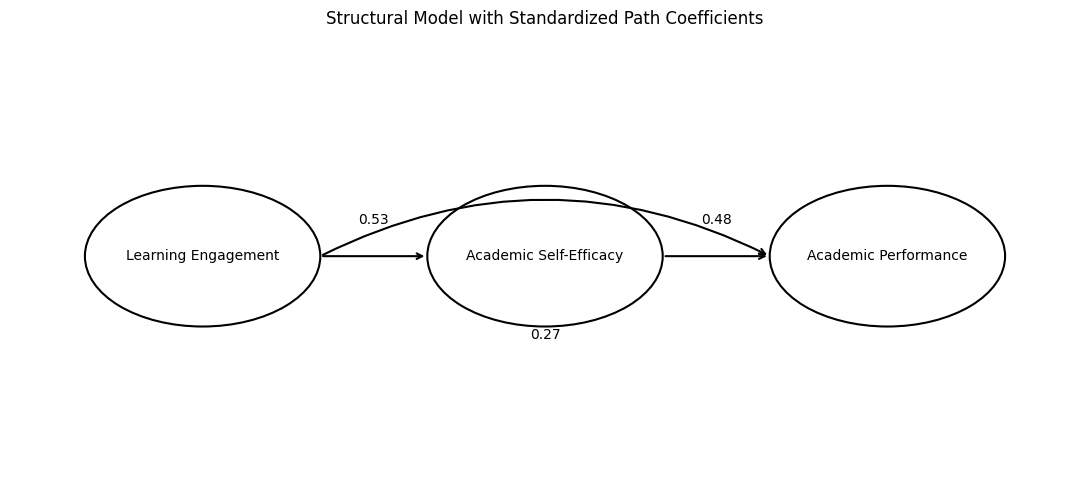

In [17]:
fig,ax=plt.subplots(figsize=(11,5))
pos={"Learning Engagement":(.18,.5),"Academic Self-Efficacy":(.5,.5),"Academic Performance":(.82,.5)}
for label,(x,y) in pos.items():
    circle=plt.Circle((x,y),.11,fill=False,linewidth=1.5)
    ax.add_patch(circle); ax.text(x,y,label,ha="center",va="center",fontsize=10,wrap=True)

edges=[
("Learning Engagement","Academic Self-Efficacy",a,0),
("Academic Self-Efficacy","Academic Performance",b,0),
("Learning Engagement","Academic Performance",direct,-.25)]
for src,dst,beta,rad in edges:
    x1,y1=pos[src]; x2,y2=pos[dst]
    ax.annotate("",xy=(x2-.11,y2),xytext=(x1+.11,y1),
                arrowprops=dict(arrowstyle="->",lw=1.5,connectionstyle=f"arc3,rad={rad}"))
    ax.text((x1+x2)/2,y1+(.05 if rad==0 else -.13),f"{beta:.2f}",ha="center")

ax.set_xlim(0,1); ax.set_ylim(.15,.85); ax.axis("off")
ax.set_title("Structural Model with Standardized Path Coefficients")
plt.tight_layout(); plt.show()

## 22. What Full SEM Adds / 本来のSEMでは何が追加されるか

Full-information SEM software estimates all parameters simultaneously and can provide global model-fit statistics such as:

- Chi-square
- CFI
- TLI
- RMSEA
- SRMR

It also estimates measurement error explicitly.

今回の学習用2段階分析では、これらの「モデル全体の適合度」を正式には算出していません。

実務・研究で本格的にSEMを行う場合は、Pythonでは `semopy`、Rでは `lavaan` などのSEM専用パッケージが代表的です。

## 23. Conceptual Model-Fit Evaluation / モデル適合度という考え方

SEM asks a broader question than ordinary regression:

> Can the proposed model reproduce the covariance relationships observed in the data?

This is why SEM evaluates the model as a whole, not only individual coefficients.

SEMでは個々のp値だけでなく、「仮説モデル全体が観測された共分散構造をどの程度再現できるか」を評価します。

## 24. SEM vs Factor Analysis / SEMと因子分析

Factor Analysis focuses mainly on relationships between latent factors and observed indicators.

SEM additionally models relationships among latent constructs.

因子分析で「潜在概念を測る」、パス解析で「矢印をつなぐ」。

SEMはその2つを統合したもの、と考えると整理しやすくなります。

## 25. SEM vs Path Analysis / SEMとパス解析

Path Analysis:
- observed variables
- direct and indirect paths

SEM:
- observed variables
- latent variables
- measurement model
- structural model
- overall model-fit evaluation

13章は、12章のパス解析に「測定モデル」を追加した章です。

## 26. Important Warning: SEM Does Not Prove Causality / SEMでも因果は証明されない

Arrows represent hypotheses, not automatic proof of causality.

Causal interpretation requires strong assumptions and appropriate research design.

SEMの図は因果関係のように見えますが、矢印を書くだけで因果が証明されるわけではありません。

## 27. Assumptions and Limitations / 前提条件と限界

Important considerations:

- adequate sample size
- theoretically justified model specification
- reliable measurement indicators
- approximate linear relationships
- distributional assumptions depend on the estimator
- missing data and outliers require attention
- alternative models may explain the data similarly
- fit indices should not be used mechanically
- this dataset is simulated
- this Notebook uses a two-step educational approximation rather than simultaneous full SEM estimation

特に重要なのは「統計ソフトがモデルを作る」のではなく、「理論に基づいて分析者がモデルを仮定する」という点です。

## 28. Conclusion / まとめ

This Notebook introduced the core structure of SEM through three latent constructs:

- Learning Engagement
- Academic Self-Efficacy
- Academic Performance

Workflow:

1. Define latent constructs
2. Choose observed indicators
3. Inspect correlations
4. Estimate one-factor measurement models
5. Create latent scores
6. Estimate structural paths
7. Calculate direct and indirect effects
8. Visualize the structural model
9. Understand full SEM model-fit evaluation
10. Discuss assumptions and causal limitations

The key idea is:

> SEM combines a measurement model with a structural path model.

つまり、

**Factor Analysis + Path Analysis → SEM**

という理解が、この章の入口として非常に重要です。

これで01の重回帰から始まった流れが、12のパス解析を経て、潜在変数を扱う13のSEMまでつながります。